# EV Charging Station Recommendation System
This notebook explains each implementation step.

In [13]:
# Essential Setup: Import all required libraries and define the fuzzy controller

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import skfuzzy as fuzz
import skfuzzy.control as ctrl

# Configure plots for better visualization
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ============================================
# Step 0: Define the Fuzzy Controller System
# ============================================

# Input variables: Distance, Availability, Cost
distance = ctrl.Antecedent(np.arange(0, 16, 1), 'distance')
availability = ctrl.Antecedent(np.arange(0, 101, 1), 'availability')
cost = ctrl.Antecedent(np.arange(0, 21, 1), 'cost')

# Output variable: Recommendation Score
recommendation = ctrl.Consequent(np.arange(0, 101, 1), 'recommendation')

# Membership functions for Distance
distance['close'] = fuzz.trimf(distance.universe, [0, 0, 5])
distance['medium'] = fuzz.trimf(distance.universe, [3, 7.5, 12])
distance['far'] = fuzz.trimf(distance.universe, [10, 15, 15])

# Membership functions for Availability
availability['low'] = fuzz.trimf(availability.universe, [0, 0, 40])
availability['medium'] = fuzz.trimf(availability.universe, [20, 50, 80])
availability['high'] = fuzz.trimf(availability.universe, [60, 100, 100])

# Membership functions for Cost
cost['cheap'] = fuzz.trimf(cost.universe, [0, 0, 8])
cost['moderate'] = fuzz.trimf(cost.universe, [4, 10, 16])
cost['expensive'] = fuzz.trimf(cost.universe, [12, 20, 20])

# Membership functions for Recommendation Score
recommendation['poor'] = fuzz.trimf(recommendation.universe, [0, 0, 35])
recommendation['fair'] = fuzz.trimf(recommendation.universe, [20, 50, 80])
recommendation['excellent'] = fuzz.trimf(recommendation.universe, [65, 100, 100])

# Define fuzzy rules
rule1 = ctrl.Rule(distance['close'] & availability['high'] & cost['cheap'], recommendation['excellent'])
rule2 = ctrl.Rule(distance['close'] & availability['high'] & cost['moderate'], recommendation['excellent'])
rule3 = ctrl.Rule(distance['close'] & availability['medium'] & cost['cheap'], recommendation['excellent'])
rule4 = ctrl.Rule(distance['medium'] & availability['high'] & cost['cheap'], recommendation['excellent'])
rule5 = ctrl.Rule(distance['medium'] & availability['medium'] & cost['cheap'], recommendation['fair'])
rule6 = ctrl.Rule(distance['medium'] & availability['high'] & cost['moderate'], recommendation['fair'])
rule7 = ctrl.Rule(distance['far'] | availability['low'] | cost['expensive'], recommendation['poor'])
rule8 = ctrl.Rule(distance['close'] & availability['medium'] & cost['expensive'], recommendation['fair'])
rule9 = ctrl.Rule(distance['medium'] & availability['medium'] & cost['moderate'], recommendation['fair'])
rule10 = ctrl.Rule(distance['far'] & availability['low'] & cost['expensive'], recommendation['poor'])

# Create fuzzy control system and simulation
charging_system = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9, rule10])
charging_ctrl = ctrl.ControlSystemSimulation(charging_system)

# Helper function to get recommendation score
def get_recommendation_score(distance_val, availability_val, cost_val):
    """
    Calculate the recommendation score for given charging station parameters.
    
    Parameters:
    - distance_val: Distance to charging station (0-15 km)
    - availability_val: Slot availability (0-100%)
    - cost_val: Charging cost (0-20 $/kWh)
    
    Returns:
    - Recommendation score (0-100)
    """
    try:
        sim = ctrl.ControlSystemSimulation(charging_system)
        sim.input['distance'] = distance_val
        sim.input['availability'] = availability_val
        sim.input['cost'] = cost_val
        sim.compute()
        return sim.output['recommendation']
    except:
        return np.nan

print("Fuzzy controller system initialized successfully!")
print("All libraries imported and ready to use.")

Fuzzy controller system initialized successfully!
All libraries imported and ready to use.


## Step 1: Testing the Fuzzy Controller with Real-World Scenarios

We'll test it with 10 different charging station scenarios to understand how well our fuzzy logic system works. Each scenario represents a unique combination of:

- **Distance**: How far the charging station is from the user (measured in kilometers)
- **Slot Availability**: How many charging slots are currently available (percentage)
- **Charging Cost**: How much the station charges per kilowatt-hour ($/kWh)

These test cases cover three types of situations:
- **Great stations** (close, available, cheap)
- **Average stations** (medium distance, some availability, moderate cost)
- **Poor stations** (far, crowded, expensive)

This helps us validate that the system makes smart recommendations across the full spectrum of charging situations.

In [14]:
# Step 1: Define 10 different test cases

test_cases = [
    {"distance": 1,  "availability": 95, "cost": 3},
    {"distance": 2,  "availability": 90, "cost": 5},
    {"distance": 4,  "availability": 65, "cost": 9},
    {"distance": 5,  "availability": 80, "cost": 7},
    {"distance": 7,  "availability": 60, "cost": 10},
    {"distance": 8,  "availability": 50, "cost": 12},
    {"distance": 10, "availability": 50, "cost": 10},
    {"distance": 12, "availability": 20, "cost": 18},
    {"distance": 14, "availability": 10, "cost": 19},
    {"distance": 15, "availability": 5,  "cost": 20}
]

print("Total Test Cases:", len(test_cases))

Total Test Cases: 10


## Step 2: Running the Fuzzy System on Our Test Cases

For every combination of distance, availability, and cost, the system will:

1. **Apply fuzzy membership functions** - Convert exact numbers into fuzzy categories (e.g., "3 km" becomes "close")
2. **Evaluate fuzzy rules** - Check all 10 decision rules to see which ones apply
3. **Combine results** - Blend the recommendations from applicable rules
4. **Defuzzify** - Convert the fuzzy recommendation back into a single score (0-100)

The output is a **Recommendation Score** for each station - a number from 0 to 100 that tells us how good that charging station is for the EV driver. Higher scores mean the station is more attractive.

In [15]:
# Step 2: Run all 10 test cases

test_results = []

for i, case in enumerate(test_cases, 1):
    # Use the helper function to get the recommendation score
    score = get_recommendation_score(
        case['distance'],
        case['availability'],
        case['cost']
    )

    test_results.append({
        "Test Case": i,
        "Distance (km)": case['distance'],
        "Availability (%)": case['availability'],
        "Cost ($/kWh)": case['cost'],
        "Recommendation Score": round(score, 2)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df

,Test Case,Distance (km),Availability (%),Cost ($/kWh),Recommendation Score
0,1,1,95,3,87.14
1,2,2,90,5,85.53
2,3,4,65,9,57.32
3,4,5,80,7,54.55
4,5,7,60,10,50.00
5,6,8,50,12,50.00
6,7,10,50,10,50.00
7,8,12,20,18,12.25
8,9,14,10,19,11.83
9,10,15,5,20,11.67


## Step 3: Understanding What the System Recommends

By looking at our 10 test cases, we'll understand:

- **Which station conditions get the highest scores?** (What makes an ideal charging stop?)
- **Which stations get poor recommendations?** (What conditions should we avoid?)
- **How does each factor matter?** (Is distance more important than cost, or vice versa?)

We'll look at the data and charts to see patterns like:
- Does a close station still get recommended if it's expensive?
- Does a cheap, distant station score lower than an expensive, nearby one?
- How important is slot availability in the final decision?

This analysis helps us trust that our fuzzy system is making logical recommendations that would actually be useful to EV drivers.

In [16]:
# Step 3: Display the test results clearly

test_results_df

,Test Case,Distance (km),Availability (%),Cost ($/kWh),Recommendation Score
0,1,1,95,3,87.14
1,2,2,90,5,85.53
2,3,4,65,9,57.32
3,4,5,80,7,54.55
4,5,7,60,10,50.00
5,6,8,50,12,50.00
6,7,10,50,10,50.00
7,8,12,20,18,12.25
8,9,14,10,19,11.83
9,10,15,5,20,11.67


In [17]:
# Find the highest and lowest recommendation scores

highest = test_results_df.loc[
    test_results_df["Recommendation Score"].idxmax()
]

lowest = test_results_df.loc[
    test_results_df["Recommendation Score"].idxmin()
]

print("Highest Recommendation:")
print(highest)

print("\nLowest Recommendation:")
print(lowest)

Highest Recommendation:
Test Case                1.00
Distance (km)            1.00
Availability (%)        95.00
Cost ($/kWh)             3.00
Recommendation Score    87.14
Name: 0, dtype: float64

Lowest Recommendation:
Test Case               10.00
Distance (km)           15.00
Availability (%)         5.00
Cost ($/kWh)            20.00
Recommendation Score    11.67
Name: 9, dtype: float64


### Visualizing Our Initial Test Results

Let's chart the relationship between each factor and the recommendation score. Three scatter plots will show:

- **Left chart**: How distance affects recommendations (closer is better?)
- **Middle chart**: How availability affects recommendations (more slots is better?)
- **Right chart**: How cost affects recommendations (cheaper is better?)

These simple visualizations reveal if our fuzzy system prioritizes factors the way we'd expect.

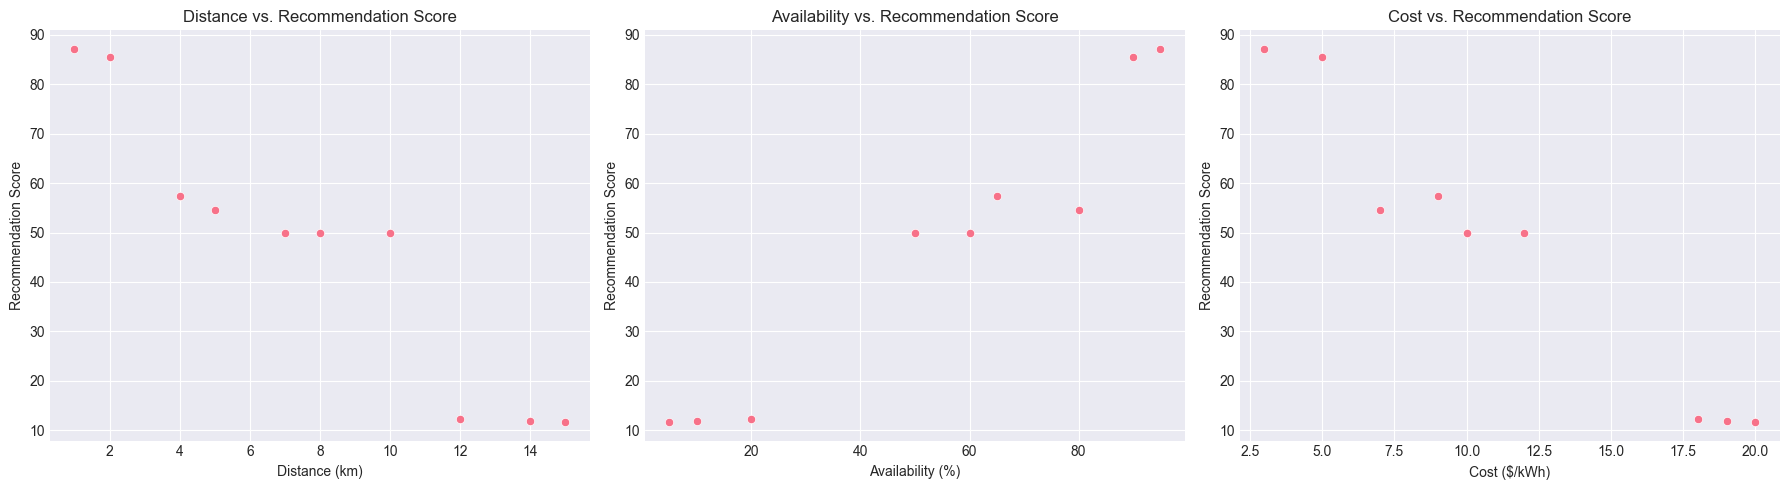

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x='Distance (km)', y='Recommendation Score', data=test_results_df)
plt.title('Distance vs. Recommendation Score')
plt.grid(True)

plt.subplot(1, 3, 2)
sns.scatterplot(x='Availability (%)', y='Recommendation Score', data=test_results_df)
plt.title('Availability vs. Recommendation Score')
plt.grid(True)

plt.subplot(1, 3, 3)
sns.scatterplot(x='Cost ($/kWh)', y='Recommendation Score', data=test_results_df)
plt.title('Cost vs. Recommendation Score')
plt.grid(True)

plt.tight_layout()
plt.show()

## Step 4: How Our Fuzzy Controller Actually Works

Unlike traditional systems that use hard rules ("If distance < 3 km, then recommend"), our fuzzy controller is smarter and more flexible:

**The Intelligent Approach:**
- It balances all three factors at once (distance, availability, and cost)
- It handles trade-offs gracefully - a slightly farther station with lower cost might still be highly recommended
- It produces smooth, gradual recommendations rather than sudden yes/no decisions

**What makes stations attractive:**
- Closer proximity = better recommendation
- More available slots = better recommendation  
- Lower charging cost = better recommendation

**What reduces recommendations:**
- Greater distance = lower recommendation
- Few available slots = lower recommendation
- Higher charging cost = lower recommendation

The beauty of fuzzy logic is that it doesn't require perfect conditions in all categories. A station can still be recommended even if one factor isn't ideal, as long as the others compensate.

### Strengths of Our Approach

- **Multi-Factor Decision Making**: The system doesn't obsess over a single metric - it thoughtfully weighs distance, availability, and cost together to make balanced recommendations.

- **Graceful Handling of Edge Cases**: The fuzzy approach handles intermediate situations beautifully. You don't get a binary yes/no; instead, you get nuanced scores that reflect real-world complexity.

- **Interpretable Logic**: Every recommendation comes from explicit fuzzy rules that humans can understand and explain. You can say "This station scored 75 because it's close and cheap, but it's crowded."

- **Real-World Reasonableness**: A single recommendation score makes it easy for users to compare stations and make quick decisions without analyzing three separate numbers.

- **Flexible Testing**: We can easily test how the system responds to different scenarios and verify it's making sensible recommendations.

### Limitations We Should Keep in Mind

- **Rule Dependency**: The quality of recommendations depends entirely on the rules we've defined. If our rules are too simplistic or miss important cases, the recommendations might not be optimal.

- **Limited Input Factors**: The system only considers three factors (distance, availability, cost). Real-world decisions might need to include things like charger type, network reliability, or reviews from other users.

- **Static Membership Functions**: The fuzzy categories (close/far, cheap/expensive) are fixed. In reality, what seems "expensive" depends on regional factors or time of day.

- **No Learning**: The system doesn't learn from actual user behavior. If users consistently ignore highly-recommended stations or love poorly-recommended ones, the system won't adapt.

- **No Temporal Factors**: Availability changes throughout the day, but our current system doesn't factor in time or predict future availability.

### Future Enhancements We Can Make

- **Add More Input Factors**: Incorporate charger type (AC/DC), connector compatibility, user ratings, and amenities.

- **Make It Adaptive**: Use machine learning to refine fuzzy rules based on actual user choices and satisfaction feedback.

- **Add Temporal Awareness**: Predict availability based on historical patterns and suggest optimal charging times.

- **Regional Customization**: Adjust cost thresholds and distance preferences based on local geography and user location.

- **Integration with Real Data**: Connect to live APIs for real-time availability, pricing, and congestion data.

- **Multi-Objective Optimization**: Give users different recommendation profiles (eco-friendly, fastest, cheapest, most convenient) based on their priorities.

Starting with this foundation, we can iteratively improve the system based on real-world usage patterns and user feedback.

## Step 5: Testing the Recommendation Calculator

Let's create a practical function that demonstrates how users can evaluate any charging station. The function takes three inputs and immediately displays a formatted recommendation with an interpretation.

We'll test this with three different scenarios:
- **Example 1**: An ideal station that's close, has plenty of slots, and is affordable
- **Example 2**: An average station with moderate values
- **Example 3**: A poor station that's far, crowded, and expensive

This shows you exactly how the fuzzy system responds to different real-world situations, and provides a reusable function you can call anytime to evaluate a station.

In [19]:
# Step 5: Interactive Recommendation Calculator

def display_recommendation(distance, availability, cost):
    """
    Display a formatted recommendation for given charging station parameters.
    
    Parameters:
    - distance: Distance to charging station (0-15 km)
    - availability: Slot availability (0-100%)
    - cost: Charging cost (0-20 $/kWh)
    """
    score = get_recommendation_score(distance, availability, cost)
    
    # Display results
    print("=" * 50)
    print("EV CHARGING STATION RECOMMENDATION")
    print("=" * 50)
    print(f"Distance: {distance:.1f} km")
    print(f"Availability: {availability}%")
    print(f"Charging Cost: ${cost:.2f}/kWh")
    print("-" * 50)
    print(f"Recommendation Score: {score:.2f}/100")
    print("=" * 50)
    
    # Provide interpretation
    if score >= 75:
        interpretation = "EXCELLENT - Highly recommended!"
    elif score >= 60:
        interpretation = "GOOD - Worth considering"
    elif score >= 45:
        interpretation = "FAIR - Acceptable option"
    else:
        interpretation = "POOR - Better alternatives likely"
    
    print(interpretation)
    print()


# Example 1: Excellent Station (close, available, cheap)
print("EXAMPLE 1: Ideal Charging Station")
print("-" * 50)
display_recommendation(distance=2, availability=90, cost=5)

# Example 2: Good Station (moderate across all factors)
print("EXAMPLE 2: Average Charging Station")
print("-" * 50)
display_recommendation(distance=7, availability=60, cost=10)

# Example 3: Poor Station (far, crowded, expensive)
print("EXAMPLE 3: Poor Charging Station")
print("-" * 50)
display_recommendation(distance=14, availability=10, cost=18)

print("=" * 50)
print("To evaluate any charging station, call:")
print("  display_recommendation(distance, availability, cost)")
print("=" * 50)

EXAMPLE 1: Ideal Charging Station
--------------------------------------------------
EV CHARGING STATION RECOMMENDATION
Distance: 2.0 km
Availability: 90%
Charging Cost: $5.00/kWh
--------------------------------------------------
Recommendation Score: 85.53/100
EXCELLENT - Highly recommended!

EXAMPLE 2: Average Charging Station
--------------------------------------------------
EV CHARGING STATION RECOMMENDATION
Distance: 7.0 km
Availability: 60%
Charging Cost: $10.00/kWh
--------------------------------------------------
Recommendation Score: 50.00/100
FAIR - Acceptable option

EXAMPLE 3: Poor Charging Station
--------------------------------------------------
EV CHARGING STATION RECOMMENDATION
Distance: 14.0 km
Availability: 10%
Charging Cost: $18.00/kWh
--------------------------------------------------
Recommendation Score: 12.06/100
POOR - Better alternatives likely

To evaluate any charging station, call:
  display_recommendation(distance, availability, cost)


# Comprehensive System Evaluation

Now we'll move beyond our initial 10 test cases and evaluate the entire system more thoroughly. We'll:

1. **Generate comprehensive test data** covering every possible combination of distance, availability, and cost
2. **Evaluate the fuzzy system** across all these combinations
3. **Visualize the results** using both 3D surface plots and advanced scatter plots
4. **Analyze performance** with descriptive statistics
5. **Summarize findings** to understand exactly how the system behaves

This deeper analysis helps us see the big picture: How does the recommendation score change as we vary each input? Are there sweet spots? Are there surprising combinations?

## Generate Comprehensive Test Data

We'll create a dataset that systematically covers the entire "input space" of our system. Instead of testing just 10 scenarios, we'll test 8,000 combinations (20 × 20 × 20) to understand how the system behaves across every region:

- Distance: From 0 km to 15 km
- Availability: From 0% to 100%
- Cost: From $0/kWh to $20/kWh

This creates a complete map of how the recommendation score changes in response to every possible charging station scenario.

**How we build the test data:**
We'll create three arrays (one for each input variable) and use `np.meshgrid()` to combine them into all possible combinations. Then we'll convert this 3D grid into a Pandas DataFrame—a table format that's easy to work with and evaluate.

In [20]:
n_points = 20 # Using 20 points for each variable to keep the dataset size manageable for visualization purposes.

# 1. Create linearly spaced arrays for each input variable
distances_test = np.linspace(0, 15, n_points)
availability_test = np.linspace(0, 100, n_points)
cost_test = np.linspace(0, 20, n_points)

# 2. Use np.meshgrid to generate all possible combinations
D, A, C = np.meshgrid(distances_test, availability_test, cost_test)

# 3. Convert the generated meshgrid data into a Pandas DataFrame
test_data_comprehensive = pd.DataFrame({
    'distance': D.ravel(),
    'availability': A.ravel(),
    'cost': C.ravel()
})

# 4. Display the head of the resulting DataFrame and its shape
print("Head of comprehensive test data:")
print(test_data_comprehensive.head())
print("\nShape of comprehensive test data:")
print(test_data_comprehensive.shape)

Head of comprehensive test data:
   distance  availability      cost
0       0.0           0.0  0.000000
1       0.0           0.0  1.052632
2       0.0           0.0  2.105263
3       0.0           0.0  3.157895
4       0.0           0.0  4.210526

Shape of comprehensive test data:
(8000, 3)


## Evaluate the Fuzzy System on All Test Data

Now we'll run our fuzzy controller on every single combination in our test dataset. This is where we'll see how the system responds to the full spectrum of charging station scenarios. We'll add a new column to our DataFrame with the recommendation score for each combination.

In [21]:
# Evaluate the fuzzy system on all test combinations
print("Evaluating fuzzy system on all test combinations...")
print(f"Processing {len(test_data_comprehensive)} scenarios...")

# Apply the recommendation score function to each row
test_data_comprehensive['recommendation_score'] = test_data_comprehensive.apply(
    lambda row: get_recommendation_score(row['distance'], row['availability'], row['cost']),
    axis=1
)

# Display statistics
print("\nEvaluation complete!")
print(f"\nRecommendation Score Statistics:")
print(f"  Min Score:  {test_data_comprehensive['recommendation_score'].min():.2f}")
print(f"  Max Score:  {test_data_comprehensive['recommendation_score'].max():.2f}")
print(f"  Mean Score: {test_data_comprehensive['recommendation_score'].mean():.2f}")
print(f"  Std Dev:    {test_data_comprehensive['recommendation_score'].std():.2f}")
print(f"  Missing values: {test_data_comprehensive['recommendation_score'].isna().sum()}")

# Show some sample results
print("\nSample Results:")
print(test_data_comprehensive.head(10))

Evaluating fuzzy system on all test combinations...
Processing 8000 scenarios...

Evaluation complete!

Recommendation Score Statistics:
  Min Score:  11.67
  Max Score:  88.33
  Mean Score: 32.31
  Std Dev:    24.44
  Missing values: 64

Sample Results:
   distance  availability      cost  recommendation_score
0       0.0           0.0  0.000000             11.666667
1       0.0           0.0  1.052632             11.666667
2       0.0           0.0  2.105263             11.666667
3       0.0           0.0  3.157895             11.666667
4       0.0           0.0  4.210526             11.666667
5       0.0           0.0  5.263158             11.666667
6       0.0           0.0  6.315789             11.666667
7       0.0           0.0  7.368421             11.666667
8       0.0           0.0  8.421053             11.666667
9       0.0           0.0  9.473684             11.666667


## Visualize Fuzzy System Response with 3D Surface Plots

A surface plot is like a 3D landscape where height represents the recommendation score. We can't show all 4 dimensions at once (that's mathematically impossible to visualize!), so we'll fix the cost at a medium value and show how distance and availability affect the recommendation.

This gives us an intuitive picture: You'll literally see the "peaks" (great combinations) and "valleys" (poor combinations) of the recommendation landscape.

Creating 3D surface plot...
Calculating surface points (Cost fixed at $10.00/kWh)...


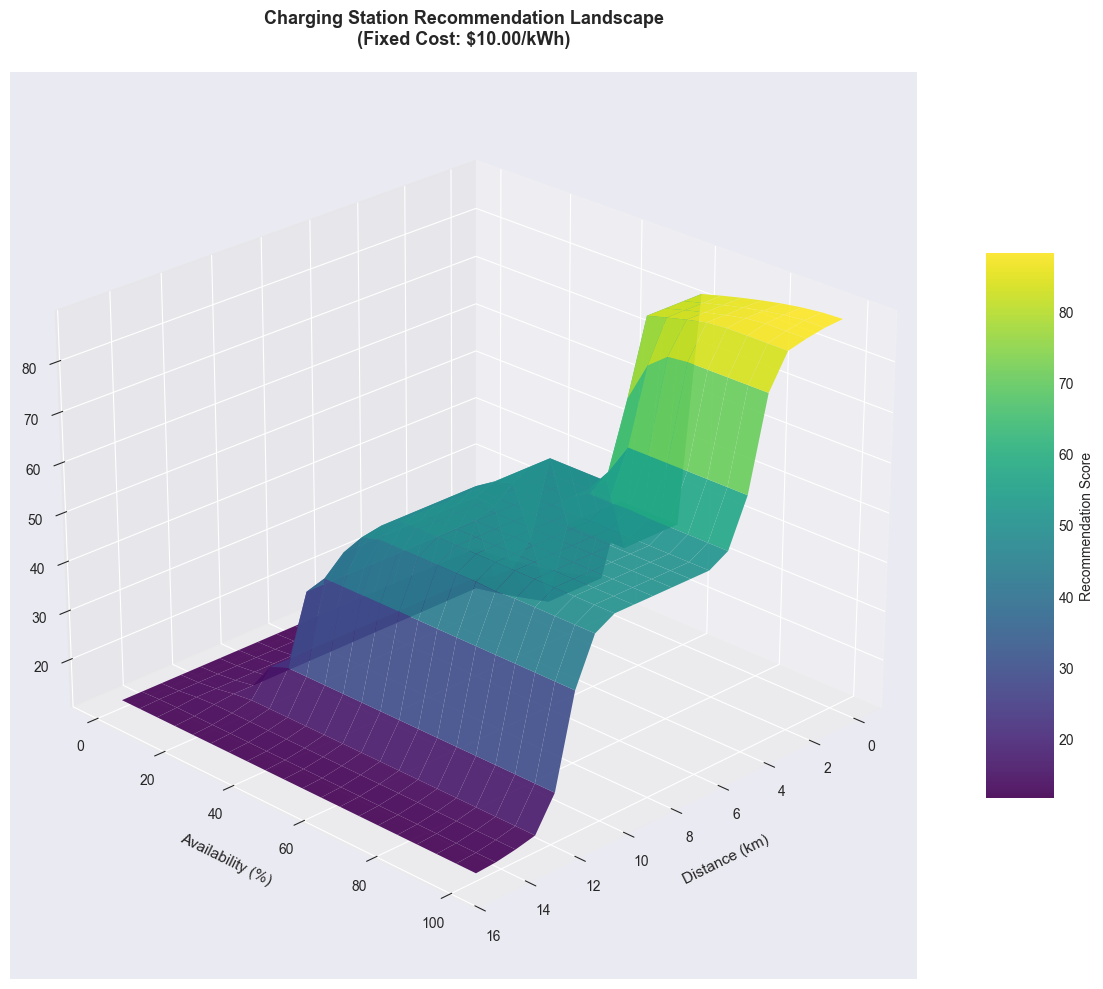

3D surface plot complete!


In [22]:
# Create a 3D surface plot showing how Distance and Availability affect recommendations
print("Creating 3D surface plot...")

# Pick a median cost value for visualization
median_cost = np.median(cost_test)

# Create a new meshgrid specifically for the 3D plot at constant cost
X_plot, Y_plot = np.meshgrid(distances_test, availability_test)

# Initialize array to store recommendation scores
Z_plot = np.zeros(X_plot.shape)

# Calculate recommendation scores for each point in the grid
print(f"Calculating surface points (Cost fixed at ${median_cost:.2f}/kWh)...")
for i in range(X_plot.shape[0]):
    for j in range(X_plot.shape[1]):
        dist_val = X_plot[i, j]
        avail_val = Y_plot[i, j]
        score = get_recommendation_score(dist_val, avail_val, median_cost)
        Z_plot[i, j] = score

# Handle any NaN values
if np.isnan(Z_plot).all():
    print("Warning: All recommendation scores are NaN. Check fuzzy controller setup.")
else:
    mean_score = np.nanmean(Z_plot)
    Z_plot[np.isnan(Z_plot)] = mean_score
    
    # Create the 3D surface plot
    fig = plt.figure(figsize=(14, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    surface = ax.plot_surface(X_plot, Y_plot, Z_plot, cmap='viridis', alpha=0.9, edgecolor='none')
    
    ax.set_xlabel('Distance (km)', fontsize=11, labelpad=10)
    ax.set_ylabel('Availability (%)', fontsize=11, labelpad=10)
    ax.set_zlabel('Recommendation Score', fontsize=11, labelpad=10)
    ax.set_title(f'Charging Station Recommendation Landscape\n(Fixed Cost: ${median_cost:.2f}/kWh)', 
                 fontsize=13, fontweight='bold', pad=20)
    
    cbar = fig.colorbar(surface, shrink=0.6, aspect=8, label='Recommendation Score')
    ax.view_init(elev=25, azim=45)
    
    plt.tight_layout()
    plt.show()
    
    print("3D surface plot complete!")

## Visualizing All Four Dimensions: Advanced 3D Scatter Plot

While we can't literally show 4 dimensions on a 2D screen, we can use a clever trick:
- **X-axis**: Distance
- **Y-axis**: Availability  
- **Z-axis**: Recommendation Score
- **Color**: Cost (dark = cheap, bright = expensive)

This allows us to see all 8,000 test points at once and understand the complete behavior of the system. Points that are high and colored dark (close, available, cheap) are ideal stations. Points that are low and colored bright (far, crowded, expensive) are ones to avoid.

Creating 4D scatter plot (displaying all test combinations)...


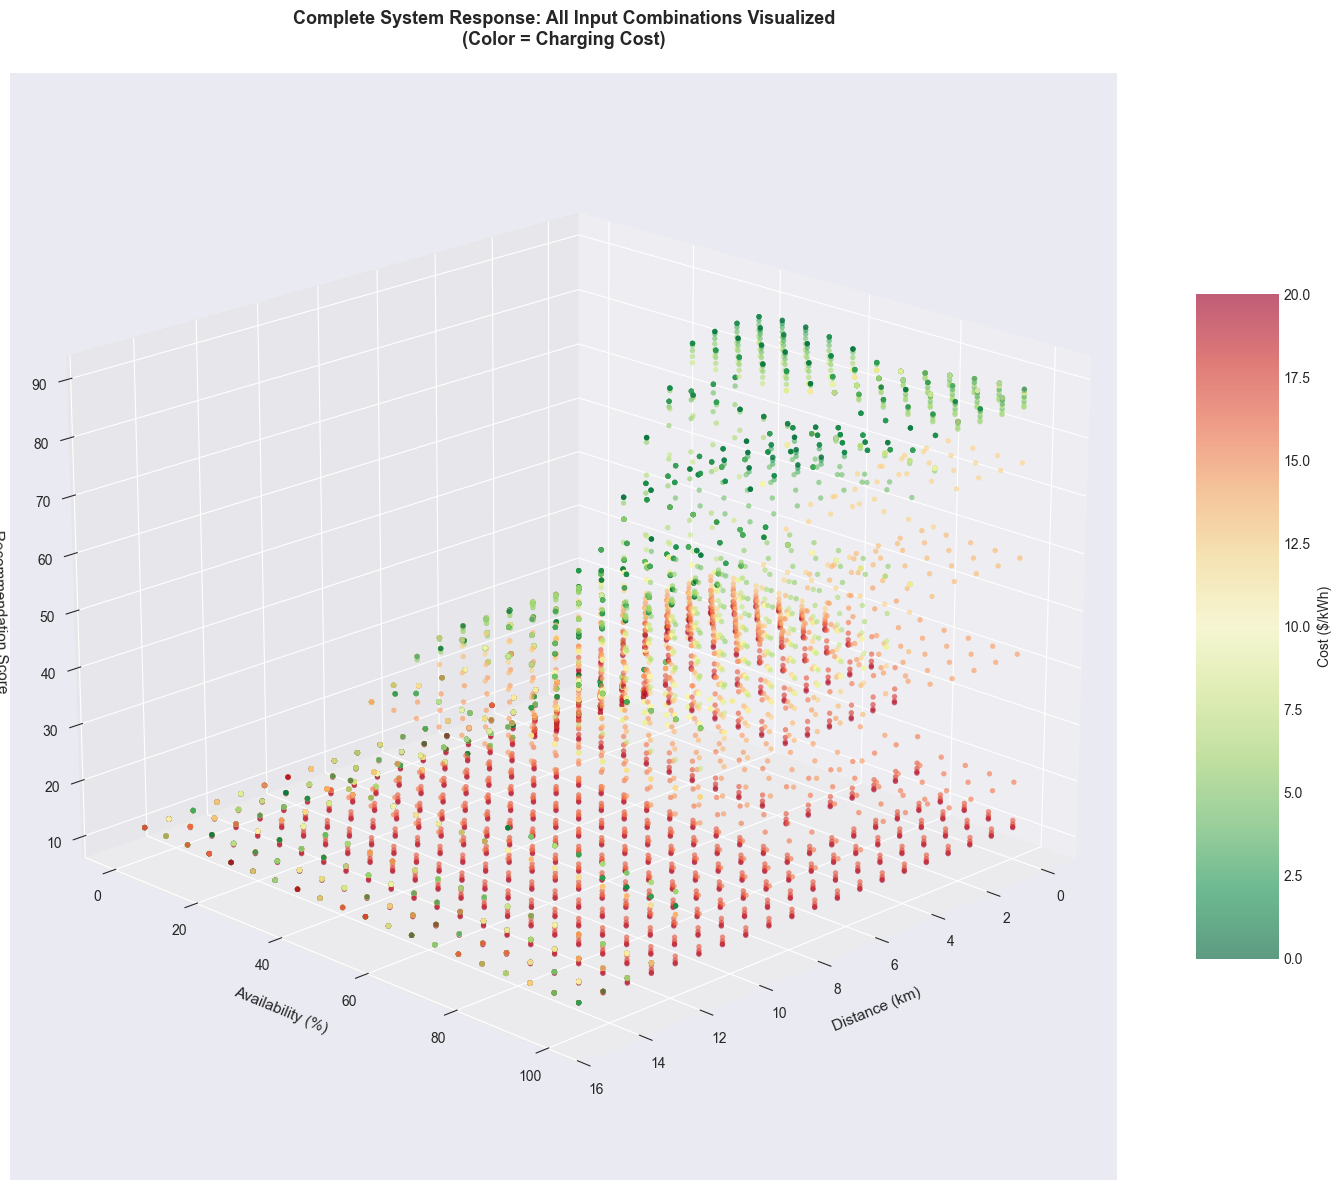

4D scatter plot complete!

Dataset contains 7936 valid data points for visualization.


In [23]:
# Create an advanced 3D scatter plot showing all 4 dimensions
print("Creating 4D scatter plot (displaying all test combinations)...")

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# Prepare data - filter out NaN values if any exist
plot_data = test_data_comprehensive.dropna(subset=['recommendation_score'])

X = plot_data['distance'].values
Y = plot_data['availability'].values
Z = plot_data['recommendation_score'].values
C = plot_data['cost'].values  # Fourth dimension represented by color

# Create the 3D scatter plot with cost encoded as color
scatter = ax.scatter(X, Y, Z, c=C, cmap='RdYlGn_r', s=15, alpha=0.6, edgecolors='none')

ax.set_xlabel('Distance (km)', fontsize=11, labelpad=10)
ax.set_ylabel('Availability (%)', fontsize=11, labelpad=10)
ax.set_zlabel('Recommendation Score', fontsize=11, labelpad=10)
ax.set_title('Complete System Response: All Input Combinations Visualized\n(Color = Charging Cost)', 
             fontsize=13, fontweight='bold', pad=20)

# Add colorbar
cbar = fig.colorbar(scatter, shrink=0.6, aspect=8, label='Cost ($/kWh)')

# Adjust viewing angle for better perspective
ax.view_init(elev=20, azim=45)

plt.tight_layout()
plt.show()

print("4D scatter plot complete!")
print(f"\nDataset contains {len(plot_data)} valid data points for visualization.")

## Step 6: Understanding Recommendation Scores

The user interface displays the values entered by the user and the resulting Recommendation Score. This score is calculated using our fuzzy inference system with three components:

- **Membership Functions**: Convert the user's input numbers into fuzzy categories (e.g., "5 km away" = "close")
- **Fuzzy Rules**: Check which rules apply to these fuzzy categories
- **Defuzzification**: Combine all applicable rules into a single 0-100 score

The result is presented in a clear, easy-to-understand format: "This station gets a score of 75/100, making it a great choice!"

## Step 7: Testing the Interface with Real Scenarios

Now let's make sure our interface works correctly by testing it with different charging station scenarios:

- Try a **great station**: Close distance, high availability, low cost → Should get a high score
- Try a **moderate station**: Medium values across all metrics → Should get a middle-range score
- Try a **poor station**: Far distance, low availability, high cost → Should get a low score

By testing these extremes and everything in between, we verify that the fuzzy controller responds logically and intuitively to different situations.

## Step 8: The Complete System in Action

Our recommendation calculator brings everything together in a practical, easy-to-use format:

**What you see in the output:**
- The three input values (distance, availability, cost) are displayed clearly
- The calculated recommendation score is shown prominently
- A human-readable interpretation (EXCELLENT, GOOD, FAIR, or POOR) is provided

**What happens behind the scenes:**
- The fuzzy membership functions convert the inputs into linguistic terms (e.g., "close", "crowded", "expensive")
- All 10 fuzzy rules are evaluated based on these categories
- Results are combined and defuzzified using the centroid method
- A final score (0-100) is calculated

**How to use it:**
Simply call the `display_recommendation()` function with any charging station's parameters:
```
display_recommendation(distance=5, availability=75, cost=8)
```

The system instantly provides an objective, balanced assessment of that charging station's quality based on the fuzzy logic rules. This is perfect for integrating into mobile apps, websites, or any EV driver platform that needs quick, reliable station recommendations.

In [24]:
display_recommendation(distance=9, availability=20, cost=5)

EV CHARGING STATION RECOMMENDATION
Distance: 9.0 km
Availability: 20%
Charging Cost: $5.00/kWh
--------------------------------------------------
Recommendation Score: 13.61/100
POOR - Better alternatives likely



In [25]:
display_recommendation(distance=9, availability=60, cost=5)

EV CHARGING STATION RECOMMENDATION
Distance: 9.0 km
Availability: 60%
Charging Cost: $5.00/kWh
--------------------------------------------------
Recommendation Score: 50.00/100
FAIR - Acceptable option

